# Lecture 7: Clustering with k-means and non-negative matrix factorization
In this lecture we will cover the following:

- What is a clustering problem?
- The k-means algorithm, uses and shortcomings.
- non-negative matrix factorization

In [21]:
import numpy as np
import sklearn
import matplotlib.pyplot as plt

## Part 1: Clustering with k-means.
### What is a clustering problem?
The standard set-up is the following: $\mathcal{X} = \{\mathbf{x}_1,\ldots,\mathbf{x}_{n}\}$ belong to $k$ unknown classes. Want to partition $\mathcal{X} = \mathcal{X}_1\cup\mathcal{X}_2\cup\ldots\cup\mathcal{X}_k$

### Discussion.
- What if we don't know $k$?
- What if we want some of the $\mathcal{X}_i$ to overlap?
- What if $k$ and $n$ are very large, and we only want to find a few of the $\mathcal{X}_i$? 

(150, 2)


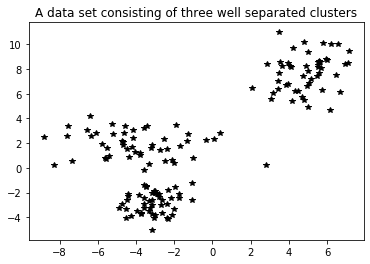

In [22]:
# Lets generate three classes in R^2 drawn from Gaussians.
mean_1 = [-3,-3]
cov_1 = [[1,0],[0,1]]
mean_2 = [-4,2]
cov_2 = [[3,0],[0,1]]
mean_3 = [5,8]
cov_3 = [[2,1],[1,2]]
#cov_3 = [[1,3],[3,1]]

# Generate the data using np.random library
X_1 = np.random.multivariate_normal(mean_1,cov_1,50)
X_2 = np.random.multivariate_normal(mean_2,cov_2,50)
X_3 = np.random.multivariate_normal(mean_3,cov_3,50)

X = np.concatenate([X_1,X_2,X_3],axis = 0) # concatenate data into single matrix
n = 150 # number of data points

print(X.shape) # check that we have done the concatenation correctly.

# Plot the data using pyplot
plt.plot(X_1[:,0],X_1[:,1],'k*')
plt.plot(X_2[:,0],X_2[:,1],'k*')
plt.plot(X_3[:,0],X_3[:,1],'k*')
plt.title('A data set consisting of three well separated clusters')
plt.show()

**Discussion**
- Any questions on code?
- What are the restrictions for a matrix to be a covariance matrix?
- Experiment with moving clusters closer together.
- Discuss elongation.

### The k-means algorithm
**Idea** (for three clusters, *i.e.* k = 3)
- Keep track of three clusters centers: $\mu_1,\mu_2,\mu_3$
- assign each data point $\mathbf{x}_i$ to $\mathcal{X}_a$ if it is closest to $\mu_a$.
- redefine $\mu_a$ as the mean/center point (technically: centroid) of $\mathcal{X}_a$. That is: $\mu_{a} = \frac{1}{n_a}\sum_{\mathbf{x}_j\in\mathcal{X}_a} \mathbf{x}_{j}$ where $n_a = |\mathcal{X}_a|$ is the number of data points in $\mathcal{X}_a$. 
- Repeat.

In [23]:
# A simple implementation of the k-means algorithm
Partition_vec = np.random.randint(0, high = 3,size = (n,1))
print(Partition_vec[0:9])

[[1]
 [2]
 [0]
 [2]
 [2]
 [1]
 [1]
 [1]
 [0]]


In [24]:
 for i in range(0,50):
        TempCentroids = np.zeros([3,2]) # Will store coordinates of centroids here.
        for a in range(0,3):
            TempInds = np.ndarray.flatten(Partition_vec == a) # Pick out indices of data points in cluster a.
            TempCluster = X[TempInds,:] # Pick out coordinates of data points in cluster a.
            TempCentroids[a] = np.mean(TempCluster,axis = 0, keepdims = True) # Compute the centroid.
            # print(TempCentroid)
        # Now, reassign data points to cluster whose centroid they are closest to.
        for j in range(0,n):
            Distances_to_Centroids = np.zeros([3,1])
            for a in range(0,3):
                Distances_to_Centroids[a] = np.linalg.norm(X[j,:] - TempCentroids[a,:])
            Partition_vec[j] = np.argmin(Distances_to_Centroids)

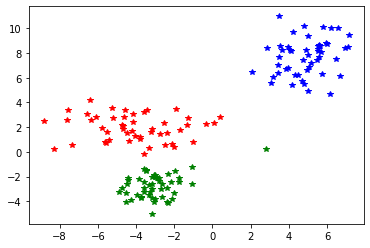

In [25]:
# Let's view our results:
colors = ['r', 'g', 'b']
for a in range(0,3):
    TempInds = np.ndarray.flatten(Partition_vec == a) # Pick out indices of data points in cluster a.
    TempCluster = X[TempInds,:] # Pick out coordinates of data points in cluster a.
    plt.plot(TempCluster[:,0],TempCluster[:,1], colors[a] + '*')
plt.show()

Pretty good right? Let's conclude by discussing some important points regarding k-means.
1. **k-means as an optimization problem**.
    - Let $\Pi\in\{0,1,2\}^{150}$ denote any *partition vector*.
    - Given any $\Pi$ we can define the centroids: $\mu_{a} = \frac{1}{n_a}\sum_{j: \Pi_{j} = a} \mathbf{x}_{j}$.
    - Define the following *quality score* for $\Pi$ $Q(\Pi) = \sum_{a=1}^{3}\sum_{j: \Pi_{j} = a} \|\mu_{a} - \mathbf{x}_{j}\|_{2}^{2}$.
    - The k-means problem: Find $\Pi^{*} := \text{argmin}_{\Pi}Q(\Pi)$. 
    - Technically, what people call the k-means algorithm is really *Lloyd's algorithm* which approximately solves the k-means problem.
    - *further reading* Kernel k-means swaps out the $\ell_2$ distance for more exotic distances (kernels).
2. **Implementation Issues**
    - Use sklearn function
    - Random initialization. Standard practice is to run k-means $m$ times with $m$ different random initial partitions. Get $\Pi_1,\ldots, \Pi_{m}$. Choose one with lowest (*i.e.* best) quality score $Q(\Pi_i)$.
3. **Strengths and Weaknesses**
    - k-means works well for $\mathcal{X} = \mathcal{X}_1\cup\ldots\cup\mathcal{X}_k \subset \mathbb{R}^{d}$ if there is a partition of $\mathbb{R}^{d}$ into convex regions such that each region contains a single cluster (Voronoi diagram). 
    - k-means **will fail** otherwise!!
    - k-means requires multiple passes through the data---can be computationally too expensive for very large data sets (look up: Landmark k-means).
    - Theoretical analysis of k-means is well-developed.

# Part 2: Non-negative Matrix factorization.
**Idea** 
 - Let $X\in\mathbb{R}^{m\times n}$ be a data matrix with non-negative entries.
 - Want a decomposition/factorization $X = WH$ such that $W\in\mathbb{R}^{m\times r}$ and $H\in\mathbb{R}^{r\times n}$ are **also non-negative**.
 - **Issue** Unlike QR and LU, there is **no guarantee** a non-negative matrix factorization exists!
 - Will settle for $X \approx WH$. 

We already have many matrix factorizations (QR, LU etc). Why another one? <br/> <br/>
**Example** Text classification.
- Given $n$ text documents, choose $m$ keywords.
- Turn each document into vector $\mathbf{x}_{i}\in\mathbb{R}^{m}$ where: $x_{i,j} = $ number of times word $j$ appears in document $i$
- Combine columns into a matrix $X = [\mathbf{x}_1,\ldots,\mathbf{x}_{n}]\in\mathbb{R}^{m\times n}$. Note $X_{ij} = x_{i,j} = \#$ times word $j$ appears in document $i$.
- Suppose $X \approx WH$ with $ r \ll m$. Let $W = [\mathbf{w}_1,\ldots,\mathbf{w}_{r}]$ where $\mathbf{w}_{i}\in\mathbb{R}^{m}$. 
- **Note:** $\mathbf{x}_j = \sum_{i=1}^{r}H_{ij}\mathbf{w}_{i}$ *(Will check this for homework)*.
- **Intepretation:** The $\mathbf{w}_i$ represent topics. $H_{ij}$ represents relevance of topic $i$ to article $\mathbf{x}_j$
- **Question:** Why is non-negativity important here?

We'll now look at an example, that I took from: https://mlexplained.com/2017/12/28/a-practical-introduction-to-nmf-nonnegative-matrix-factorization/.
**Caution** This example is the transpose of what we discussed, so **rows** of $X$ correspond to documents.

In [19]:
from sklearn.datasets import fetch_20newsgroups 
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.decomposition import NMF
 
data= fetch_20newsgroups(remove=('headers', 'footers', 'quotes')).data
 
# convert the text to a tf-idf weighted term-document matrix
vectorizer = TfidfVectorizer(max_features=2000, min_df=10, stop_words='english')
X = vectorizer.fit_transform(data)
idx_to_word = np.array(vectorizer.get_feature_names())
 
# apply NMF
nmf = NMF(n_components=20, solver="mu")
H = nmf.fit_transform(X)
W = nmf.components_
 
# print the topics
 
for i, topic in enumerate(W):
 
    print("Topic {}: {}".format(i + 1, ",".join([str(x) for x in idx_to_word[topic.argsort()[-10:]]])))

Topic 1: say,did,really,right,time,know,good,people,think,don
Topic 2: information,appreciated,email,help,info,looking,hi,advance,mail,thanks
Topic 3: lord,church,christians,christian,believe,faith,christ,bible,jesus,god
Topic 4: algorithm,public,use,escrow,government,keys,clipper,encryption,chip,key
Topic 5: problem,cd,floppy,controller,ide,hard,disk,drives,scsi,drive
Topic 6: price,50,15,20,condition,offer,shipping,10,sale,00
Topic 7: image,application,server,problem,using,files,program,use,window,file
Topic 8: teams,win,hockey,play,season,players,year,games,team,game
Topic 9: pub,ftp,cc,university,cs,soon,banks,gordon,pitt,edu
Topic 10: price,oil,speed,dealer,miles,good,engine,bike,cars,car
Topic 11: memory,color,driver,bus,vga,drivers,cards,monitor,video,card
Topic 12: exactly,appreciated,work,help,program,doesn,mean,anybody,know,does
Topic 13: did,right,wanted,oh,thought,ll,wondering,got,ve,just
Topic 14: version,os,driver,nt,microsoft,files,drivers,ms,dos,windows
Topic 15: old,sa

In [39]:
print(X.shape)

(11314, 2000)


## Brief discussion on finding NMF

- Formally, looking to solve: $\displaystyle (W^{*},H^{*}) = \text{argmin} \left\{\|X - WH\|_{F}: W\in\mathbb{R}^{m\times r} \text{ and } H\in\mathbb{R}^{r\times n}\right\}$
- This is an NP-Hard problem. 
- Algorithms for this problem still an active area of research (see: https://papers.nips.cc/paper/1861-algorithms-for-non-negative-matrix-factorization.pdf)
- Below we'll present a simple approach: Alternating Least Squares (ALS), but there are plenty of packages that have good algorithms for this problem (*e.g.* sklearn.decomposition.decomposition.NMF)

### The alternating least squares algorithm (ALS)
- Initialize $W^{(1)}$ randomly or using prior data.
- Find $H^{(1)} = \text{argmin}\left\{\|X - W^{(1)}H\|_{F}^{2}: H\in\mathbb{R}^{r\times n} \right\}$
- Until convergence do:
    - $W^{(k)} = \text{argmin}\left\{\|X - WH^{(k-1)}\|_{F}^{2}: W\in\mathbb{R}^{m\times r} \right\}$
    - $H^{(k)} = \text{argmin}\left\{\|X - W^{(k)}H\|_{F}^{2}: H\in\mathbb{R}^{r\times n} \right\}$
    
 **Remarks**
 - Each sub-problem is easy (**i.e.** convex). It is essentially least squares.
 - But alternating two convex problems is no longer a convex problem.

## Summary
- 